
# Notebook 13: Preventing Data Leakage

## Objective
Understand different types of data leakage and learn how to
identify and prevent leakage during machine learning development.

## Learning Outcomes
- Understand data leakage.
- Identify target leakage and feature leakage.
- Understand train-test contamination.
- Identify preprocessing and temporal leakage.
- Demonstrate incorrect and correct workflows.
- Learn how to detect and prevent data leakage.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

n = 1000

df_leakage = pd.DataFrame({
    "Age": np.random.randint(21, 60, n),
    "Experience": np.random.randint(0, 25, n),
    "Salary": np.random.randint(20000, 120000, n),
    "Job_Satisfaction": np.random.randint(1, 6, n),
    "Work_Hours": np.random.randint(30, 65, n)
})

# Create a target variable.
leave_probability = (
    0.25
    + 0.08 * (df_leakage["Job_Satisfaction"] <= 2)
    + 0.03 * (df_leakage["Work_Hours"] > 50)
)

df_leakage["Left_Company"] = (
    np.random.random(n) < leave_probability
).astype(int)

print("Dataset shape:", df_leakage.shape)
display(df_leakage.head())

print("\nTarget distribution:")
display(df_leakage["Left_Company"].value_counts())

Dataset shape: (1000, 6)


,Age,Experience,Salary,Job_Satisfaction,Work_Hours,Left_Company
0,59,1,49165,5,33,0
1,49,16,87203,5,32,0
2,35,10,111749,5,63,0
3,28,11,24114,2,52,1
4,41,18,84965,4,52,1



Target distribution:


Left_Company
0    679
1    321
Name: count, dtype: int64

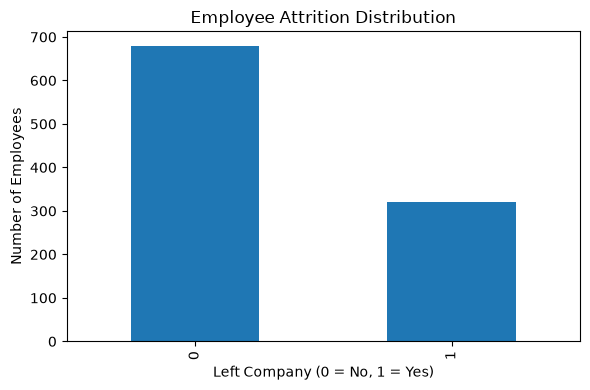

In [3]:
df_leakage["Left_Company"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Left Company (0 = No, 1 = Yes)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


## 1. What Is Data Leakage?

Data leakage occurs when information that would not legitimately
be available at prediction time enters model training or evaluation.

It can cause misleadingly high model performance.

Common types include:

1. Target leakage
2. Train-test contamination
3. Feature leakage
4. Preprocessing leakage
5. Temporal leakage

Data leakage must be prevented to ensure that model evaluation
reflects real-world performance.


In [4]:
df_target_leakage = df_leakage.copy()

# INCORRECT:
# This feature is only known after an employee leaves.
df_target_leakage["Exit_Interview_Completed"] = (
    df_target_leakage["Left_Company"]
)

X_leaked = df_target_leakage.drop(
    columns=["Left_Company"]
)

y_leaked = df_target_leakage["Left_Company"]

X_train_bad, X_test_bad, y_train_bad, y_test_bad = train_test_split(
    X_leaked,
    y_leaked,
    test_size=0.20,
    random_state=42,
    stratify=y_leaked
)

leaked_model = LogisticRegression(max_iter=1000)

leaked_model.fit(X_train_bad, y_train_bad)

leaked_predictions = leaked_model.predict(X_test_bad)

print("Accuracy with target leakage:",
      accuracy_score(y_test_bad, leaked_predictions))

Accuracy with target leakage: 1.0


In [5]:
# CORRECT:
# Remove the post-event feature.
X_clean = df_target_leakage.drop(
    columns=["Left_Company", "Exit_Interview_Completed"]
)

y_clean = df_target_leakage["Left_Company"]

X_train_clean, X_test_clean, y_train_clean, y_test_clean = (
    train_test_split(
        X_clean,
        y_clean,
        test_size=0.20,
        random_state=42,
        stratify=y_clean
    )
)

clean_model = LogisticRegression(max_iter=1000)

clean_model.fit(X_train_clean, y_train_clean)

clean_predictions = clean_model.predict(X_test_clean)

print("Accuracy without target leakage:",
      accuracy_score(y_test_clean, clean_predictions))

Accuracy without target leakage: 0.68



## 2. Feature Leakage

Feature leakage occurs when an input feature contains information
that would not legitimately be available at prediction time,
or indirectly reveals the target.

Example:

Suppose we want to predict whether a customer will default
on a loan.

Using a feature such as "Default_Recovery_Status" may reveal
information about a default that has already happened.

The feature may produce excellent test performance but cannot
be used for a genuine prediction made before the default.

How to prevent it:
- Understand when every feature becomes available.
- Check how each feature is generated.
- Remove post-outcome and future-derived information.
- Validate the feature creation process with domain knowledge.


In [6]:
feature_audit = pd.DataFrame({
    "Feature": [
        "Age",
        "Experience",
        "Salary",
        "Job_Satisfaction",
        "Work_Hours",
        "Exit_Interview_Completed"
    ],
    "Available_At_Prediction_Time": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "No"
    ],
    "Decision": [
        "Retain",
        "Retain",
        "Retain",
        "Retain",
        "Retain",
        "Remove"
    ]
})

display(feature_audit)

,Feature,Available_At_Prediction_Time,Decision
0,Age,Yes,Retain
1,Experience,Yes,Retain
2,Salary,Yes,Retain
3,Job_Satisfaction,Yes,Retain
4,Work_Hours,Yes,Retain
5,Exit_Interview_Completed,No,Remove



## 3. Train-Test Contamination

Train-test contamination occurs when information from the test
dataset influences the training process.

Examples:
- Fitting preprocessing on the complete dataset.
- Performing feature selection before splitting.
- Using test data during hyperparameter tuning.
- Allowing duplicate or related records to cross dataset boundaries.

The test dataset should remain independent of model development.


In [7]:
# INCORRECT: Fit the scaler on all observations before splitting.

scaler_bad = StandardScaler()

X_scaled_bad = scaler_bad.fit_transform(X_clean)

X_train_bad, X_test_bad, y_train_bad, y_test_bad = train_test_split(
    X_scaled_bad,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("Incorrect workflow: scaler learned from the complete dataset.")
print("Scaler mean:", scaler_bad.mean_[:3])

Incorrect workflow: scaler learned from the complete dataset.
Scaler mean: [4.0445000e+01 1.2065000e+01 6.9294063e+04]


In [8]:
# CORRECT: Split first and fit the scaler only on training data.

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

scaler_good = StandardScaler()

X_train_scaled = scaler_good.fit_transform(X_train)

X_test_scaled = scaler_good.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining means after scaling:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nTest means after applying training scaler:")
print(X_test_scaled.mean(axis=0).round(3))

Training data shape: (800, 5)
Testing data shape: (200, 5)

Training means after scaling:
[-0. -0.  0. -0.  0.]

Test means after applying training scaler:
[-0.098 -0.103  0.051  0.027 -0.069]


In [9]:
# Create missing values for demonstration.
df_missing_demo = X_clean.copy()

df_missing_demo.loc[
    df_missing_demo.sample(
        frac=0.10,
        random_state=42
    ).index,
    "Salary"
] = np.nan

# INCORRECT: Calculate median using the entire dataset.
full_data_median = df_missing_demo["Salary"].median()

df_incorrect_imputed = df_missing_demo.copy()

df_incorrect_imputed["Salary"] = (
    df_incorrect_imputed["Salary"].fillna(full_data_median)
)

print("Median calculated using all data:", full_data_median)

Median calculated using all data: 69006.0


In [10]:
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    df_missing_demo,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

preprocessing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

preprocessing_pipeline.fit(X_train_p, y_train_p)

pipeline_predictions = preprocessing_pipeline.predict(X_test_p)

print("Correct preprocessing pipeline accuracy:",
      accuracy_score(y_test_p, pipeline_predictions))

Correct preprocessing pipeline accuracy: 0.68



## 4. Temporal Leakage

Temporal leakage occurs when future information is used to predict
an event that should be predicted using only past information.

Example:

Predicting January sales using February sales information.

This creates unrealistic model performance because future information
would not be available when making the January prediction.

How to prevent it:
- Sort records by date.
- Use chronological train-validation-test splitting.
- Create lag features using past observations only.
- Avoid future-derived features.
- Ensure rolling calculations do not include future records.


In [11]:
np.random.seed(42)

df_temporal = pd.DataFrame({
    "Date": pd.date_range("2026-01-01", periods=100, freq="D"),
    "Sales": np.random.randint(100, 1000, 100)
})

# Create a future sales feature.
df_temporal["Future_Sales"] = df_temporal["Sales"].shift(-1)

# INCORRECT: Random splitting can mix past and future observations.
X_time_bad = df_temporal[["Sales", "Future_Sales"]].dropna()
y_time_bad = df_temporal.loc[X_time_bad.index, "Sales"]

X_train_time_bad, X_test_time_bad, y_train_time_bad, y_test_time_bad = (
    train_test_split(
        X_time_bad,
        y_time_bad,
        test_size=0.20,
        random_state=42
    )
)

print("Incorrect random temporal split:")
print("Training dates:",
      df_temporal.loc[X_train_time_bad.index, "Date"].min(),
      "to",
      df_temporal.loc[X_train_time_bad.index, "Date"].max())

print("Testing dates:",
      df_temporal.loc[X_test_time_bad.index, "Date"].min(),
      "to",
      df_temporal.loc[X_test_time_bad.index, "Date"].max())

Incorrect random temporal split:
Training dates: 2026-01-02 00:00:00 to 2026-04-09 00:00:00
Testing dates: 2026-01-01 00:00:00 to 2026-04-08 00:00:00


In [12]:
# CORRECT: Use chronological splitting and past information only.

df_temporal_correct = df_temporal.copy()

df_temporal_correct["Previous_Day_Sales"] = (
    df_temporal_correct["Sales"].shift(1)
)

df_temporal_correct = df_temporal_correct.dropna().reset_index(drop=True)

X_time = df_temporal_correct[["Previous_Day_Sales"]]
y_time = df_temporal_correct["Sales"]

train_end = int(len(df_temporal_correct) * 0.60)
val_end = int(len(df_temporal_correct) * 0.80)

X_train_time = X_time.iloc[:train_end]
X_val_time = X_time.iloc[train_end:val_end]
X_test_time = X_time.iloc[val_end:]

y_train_time = y_time.iloc[:train_end]
y_val_time = y_time.iloc[train_end:val_end]
y_test_time = y_time.iloc[val_end:]

print("Training dates:")
print(df_temporal_correct["Date"].iloc[:train_end].min(),
      "to",
      df_temporal_correct["Date"].iloc[:train_end].max())

print("\nValidation dates:")
print(df_temporal_correct["Date"].iloc[train_end:val_end].min(),
      "to",
      df_temporal_correct["Date"].iloc[train_end:val_end].max())

print("\nTesting dates:")
print(df_temporal_correct["Date"].iloc[val_end:].min(),
      "to",
      df_temporal_correct["Date"].iloc[val_end:].max())

Training dates:
2026-01-02 00:00:00 to 2026-02-28 00:00:00

Validation dates:
2026-03-01 00:00:00 to 2026-03-20 00:00:00

Testing dates:
2026-03-21 00:00:00 to 2026-04-09 00:00:00



## 5. How to Detect Data Leakage

Common warning signs include:

1. Unexpectedly high model accuracy.
2. Features that strongly reveal the target.
3. Features created after the prediction event.
4. Preprocessing fitted before train-test splitting.
5. Random splitting of time-dependent data.
6. Duplicate or related records across training and testing.
7. Large differences between validation and real-world performance.

Detection techniques:
- Review feature definitions and timestamps.
- Inspect feature-target relationships.
- Audit preprocessing steps.
- Compare random and time-based validation where appropriate.
- Check duplicate records and entity overlap.
- Review model performance on genuinely unseen data.

High performance alone does not prove leakage, but it should
encourage careful investigation.


In [13]:
correlation_check = df_target_leakage.corr(numeric_only=True)

target_relationship = (
    correlation_check["Left_Company"]
    .drop("Left_Company")
    .sort_values(key=abs, ascending=False)
)

print("Feature correlation with target:")
display(target_relationship.to_frame("Correlation"))

Feature correlation with target:


,Correlation
Exit_Interview_Completed,1.000000
Job_Satisfaction,-0.104738
Experience,0.066552
Salary,-0.017619
Work_Hours,-0.012009
Age,0.000215



## 6. How to Prevent Data Leakage

Follow these practices:

1. Split the dataset before fitting preprocessing methods.
2. Fit imputers and scalers only on training data.
3. Use pipelines for preprocessing and model training.
4. Remove features that reveal future outcomes.
5. Use chronological splitting for time-dependent data.
6. Perform feature selection inside the training workflow.
7. Apply resampling only to training data.
8. Use cross-validation correctly.
9. Keep the final test set untouched until final evaluation.
10. Document the source and availability time of each feature.

The goal is to simulate the information available when the model
will actually make a prediction.


In [14]:
workflow_comparison = pd.DataFrame({
    "Activity": [
        "Data splitting",
        "Missing value handling",
        "Feature scaling",
        "Feature selection",
        "Resampling",
        "Temporal validation",
        "Final evaluation"
    ],
    "Incorrect_Workflow": [
        "Split after preprocessing",
        "Impute using full dataset",
        "Fit scaler on full dataset",
        "Select features before splitting",
        "Resample before splitting",
        "Use random split for future prediction",
        "Tune repeatedly on test data"
    ],
    "Correct_Workflow": [
        "Split before learned preprocessing",
        "Fit imputer on training data",
        "Fit scaler on training data",
        "Select features using training data",
        "Resample training data only",
        "Use chronological splitting",
        "Evaluate on untouched test data"
    ]
})

display(workflow_comparison)

,Activity,Incorrect_Workflow,Correct_Workflow
0,Data splitting,Split after preprocessing,Split before learned preprocessing
1,Missing value handling,Impute using full dataset,Fit imputer on training data
2,Feature scaling,Fit scaler on full dataset,Fit scaler on training data
3,Feature selection,Select features before splitting,Select features using training data
4,Resampling,Resample before splitting,Resample training data only
5,Temporal validation,Use random split for future prediction,Use chronological splitting
6,Final evaluation,Tune repeatedly on test data,Evaluate on untouched test data


In [15]:
leakage_checklist = {
    "Split before preprocessing": True,
    "Imputer fitted on training data only": True,
    "Scaler fitted on training data only": True,
    "Future-derived features removed": True,
    "Target leakage features removed": True,
    "Test data kept separate": True,
    "Temporal order preserved where required": True
}

checklist_df = pd.DataFrame({
    "Validation_Check": leakage_checklist.keys(),
    "Completed": leakage_checklist.values()
})

display(checklist_df)

if checklist_df["Completed"].all():
    print("All demonstration checklist items passed!")
else:
    print("Some checks require attention.")

,Validation_Check,Completed
0,Split before preprocessing,True
1,Imputer fitted on training data only,True
2,Scaler fitted on training data only,True
3,Future-derived features removed,True
4,Target leakage features removed,True
5,Test data kept separate,True
6,Temporal order preserved where required,True


All demonstration checklist items passed!



## Conclusion

In this notebook, I learned about data leakage and its different
types, including target leakage, train-test contamination,
feature leakage, preprocessing leakage, and temporal leakage.

I demonstrated incorrect and correct preprocessing workflows
using Python and Scikit-learn.

I learned to split data before fitting preprocessing methods,
use pipelines, remove future-derived information, and maintain
chronological order for time-dependent problems.

Data leakage can produce misleadingly high model performance.
Preventing leakage is essential for building reliable machine
learning models that perform well on unseen real-world data.
